In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Wi-Fi CSI Data Extraction & Preprocessing Pipeline
## 2D Indoor Localization on the HALOC Dataset

This notebook implements the complete 7-stage data extraction and preprocessing pipeline to transform raw Wi-Fi Channel State Information (CSI) into sequence tensors for a **CNN-LSTM** neural network:

1. **Text-to-Number Conversion**: Parse raw stringified arrays of 256 values into numerical arrays per packet.
2. **Splitting I & Q Pairs**: Separate 256 interleaved values into 128 In-phase ($I$) and 128 Quadrature ($Q$) subcarriers.
3. **Physical Feature Calculation**: Compute Amplitude ($A = \sqrt{I^2 + Q^2}$) and Phase ($\phi = \text{arctan2}(Q, I)$) with subcarrier unwrapping.
4. **Pruning Guard Bands**: Trim null subcarrier dead zones (6 leading, 3 trailing) to keep 119 active subcarriers.
5. **Target Coordinate Extraction**: Extract planar ground-truth coordinates ($x, y$) in meters and **drop the Z-axis**.
6. **Normalization**: Per-packet Z-score normalization across subcarriers to eliminate base power drift and AGC noise.
7. **Temporal Sequencing (Sliding Windows)**: Chronologically segment packets into sliding window sequences for CNN-LSTM input.


## Environment Setup & File Path Configuration
This cell automatically detects whether you are running in **Google Colab** or **locally**, and locates your dataset files (`0.csv` or `train.csv`).

If running in Colab, make sure you have either:
1. Uploaded your CSV files via the 📁 **Files** tab on the left.
2. Or mounted Google Drive (uncomment the drive mount code below).


In [ ]:
import os
import sys
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detect Google Colab environment
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print(" Running in Google Colab environment.")
    # If your dataset is stored on Google Drive, uncomment these two lines:
    # from google.colab import drive
    # drive.mount('/content/drive')

def find_dataset_file():
    """
    Searches for dataset CSV files across common Colab and local directories.
    """
    candidates = [
        # Direct uploads in Colab
        "/content/train.csv",
        "/content/0.csv",
        "/content/dataset_splits/train.csv",
        "/content/splits/train.csv",
        "/content/HALOC/train.csv",
        "/content/HALOC/0.csv",
        "/content/HALOC/HALOC/0.csv",
        # Google Drive paths
        "/content/drive/MyDrive/HALOC/train.csv",
        "/content/drive/MyDrive/HALOC/0.csv",
        "/content/drive/MyDrive/CSIdataset/Position/HALOC/splits/train.csv",
        "/content/drive/MyDrive/CSIdataset/Position/HALOC/HALOC/0.csv",
        # Local workspace paths
        "Position/HALOC/splits/train.csv",
        "Position/HALOC/HALOC/0.csv",
        "splits/train.csv",
        "train.csv",
        "0.csv"
    ]
    for path in candidates:
        if os.path.exists(path):
            return path

    # Recursive search if not in default paths
    search_root = "/content" if IN_COLAB else "."
    for pattern in ["*train*.csv", "0.csv", "*.csv"]:
        found = glob.glob(os.path.join(search_root, "**", pattern), recursive=True)
        # Filter out Colab system sample_data and checkpoints
        valid = [f for f in found if "sample_data" not in f and ".ipynb_checkpoints" not in f]
        if valid:
            return valid[0]
    return None

DATA_PATH = find_dataset_file()

if DATA_PATH is None:
    print("❌ No dataset CSV file found in Colab!")
    print(" 👉 How to provide the dataset in Google Colab:")
    print("   Method 1: Click the 📁 (Files) icon on the left panel and upload '0.csv' or 'train.csv'.")
    print("   Method 2: If in Google Drive, run:")
    print("             from google.colab import drive; drive.mount('/content/drive')")
    print("             DATA_PATH = '/content/drive/MyDrive/Position/HALOC/splits/train.csv'")
    raise FileNotFoundError("Dataset CSV not found. Please upload 0.csv or train.csv to Colab and re-run.")
else:
    print(f" Found dataset file at: {DATA_PATH}")

# Load sample rows for verification
df = pd.read_csv(DATA_PATH, nrows=5000)
print(f" Loaded sample: {len(df):,} rows.")
print("Columns:", list(df.columns))
df[['id', 'mac', 'rssi', 'channel', 'x', 'y', 'z']].head(3)


 Running in Google Colab environment.
 Found dataset file at: /content/drive/MyDrive/Position/HALOC/splits/train.csv
 Loaded sample: 5,000 rows.
Columns: ['type', 'id', 'mac', 'rssi', 'rate', 'sig_mode', 'mcs', 'bandwidth', 'smoothing', 'not_sounding', 'aggregation', 'stbc', 'fec_coding', 'sgi', 'noise_floor', 'ampdu_cnt', 'channel', 'secondary_channel', 'local_timestamp', 'ant', 'sig_len', 'rx_state', 'len', 'first_word', 'data', 'x', 'y', 'z', 'source_file']


,id,mac,rssi,channel,x,y,z
0,403992,1a:00:00:00:00:00,-43,11,-0.004792,0.025797,1.260849
1,403993,1a:00:00:00:00:00,-43,11,-0.001213,0.025265,1.260939
2,403994,1a:00:00:00:00:00,-43,11,0.002366,0.024733,1.261029


## Step 1: Text-to-Number Conversion
The `data` column is currently stored as a string wrapped in brackets: `"[0,0,0,...,-10,-4,...]"`.
Here we parse that comma-separated text into a 2D NumPy array of shape `(N, 256)` containing raw numerical values.


In [ ]:
def text_to_csi_raw(data_series):
    """
    Converts a pandas Series of bracketed CSI text strings into
    a 2D numpy array of shape (N, 256).
    """
    raw_array = np.array([json.loads(row) for row in data_series], dtype=np.float32)
    return raw_array

raw_csi = text_to_csi_raw(df['data'])
print(f"Step 1 Complete: Raw CSI array shape = {raw_csi.shape}")
print(f"Sample first 12 raw values of Packet #0: {raw_csi[0, :12]}")


Step 1 Complete: Raw CSI array shape = (5000, 256)
Sample first 12 raw values of Packet #0: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Step 2: Splitting the I and Q Pairs
The 256 numbers in each row represent interleaved In-phase ($I$) and Quadrature ($Q$) components:
- **In-Phase ($I$)**: Even positions `0, 2, 4, ...` (1st, 3rd, 5th numbers) -> 128 subcarriers
- **Quadrature ($Q$)**: Odd positions `1, 3, 5, ...` (2nd, 4th, 6th numbers) -> 128 subcarriers


In [ ]:
def split_iq(raw_csi_array):
    """
    Splits interleaved 256 values into In-phase (I) and Quadrature (Q) components.
    Input: (N, 256)
    Output: I (N, 128), Q (N, 128)
    """
    I = raw_csi_array[:, 0::2]  # Even indices: 0, 2, 4, ...
    Q = raw_csi_array[:, 1::2]  # Odd indices: 1, 3, 5, ...
    return I, Q

I, Q = split_iq(raw_csi)
print(f"Step 2 Complete:")
print(f"  In-phase (I) shape   : {I.shape}")
print(f"  Quadrature (Q) shape : {Q.shape}")
print(f"  Packet 0 - First 5 I values: {I[0, :5]}")
print(f"  Packet 0 - First 5 Q values: {Q[0, :5]}")


Step 2 Complete:
  In-phase (I) shape   : (5000, 128)
  Quadrature (Q) shape : (5000, 128)
  Packet 0 - First 5 I values: [0. 0. 0. 0. 0.]
  Packet 0 - First 5 Q values: [0. 0. 0. 0. 0.]


## Step 3: Inspect Batch Shapes and Target Ranges
Confirm that the DataLoaders produce normalized batches with correct tensor dimensions and values strictly within $[0, 1]$.


In [ ]:
def compute_amplitude_and_phase(I, Q, unwrap_phase=True):
    """
    Calculates Amplitude and Phase from In-phase and Quadrature components.
    Input: I (N, 128), Q (N, 128)
    Output: amplitude (N, 128), phase (N, 128)
    """
    # Amplitude = sqrt(I^2 + Q^2)
    amplitude = np.sqrt(I**2 + Q**2)

    # Phase = arctan2(Q, I) in radians (-pi to +pi)
    phase = np.arctan2(Q, I)

    # Unwrap phase across subcarrier dimension (axis=1)
    if unwrap_phase:
        phase = np.unwrap(phase, axis=1)

    return amplitude, phase

amplitude, phase = compute_amplitude_and_phase(I, Q)
print(f"Step 3 Complete:")
print(f"  Amplitude shape: {amplitude.shape} | Value range: [{amplitude.min():.2f}, {amplitude.max():.2f}]")
print(f"  Phase shape    : {phase.shape}     | Value range: [{phase.min():.2f}, {phase.max():.2f}]")


Step 3 Complete:
  Amplitude shape: (5000, 128) | Value range: [0.00, 87.73]
  Phase shape    : (5000, 128)     | Value range: [-15.71, 18.85]


## Step 4: Pruning the Guard Bands (Null Subcarriers)
Wi-Fi standards allocate guard bands at both edges of the frequency band to prevent adjacent channel interference:
- **Leading Guard Band**: Subcarriers `0 to 5` (6 subcarriers of zeros)
- **Trailing Guard Band**: Subcarriers `125 to 127` (3 subcarriers of zeros)

We prune these dead zones so our neural network is not forced to process useless zeros. Remaining subcarriers = $128 - (6 + 3) = 119$ active subcarriers.


In [ ]:
def prune_guard_bands(amplitude, phase, lead_trim=6, trail_trim=3):
    """
    Trims dead guard-band zones from spectrum edges.
    Default for 128 subcarriers: trims 6 leading (0..5) and 3 trailing (125..127).
    Remaining active subcarriers: 128 - 9 = 119 subcarriers.
    """
    end_idx = amplitude.shape[1] - trail_trim
    amp_pruned = amplitude[:, lead_trim:end_idx]
    phase_pruned = phase[:, lead_trim:end_idx]
    return amp_pruned, phase_pruned

amp_pruned, phase_pruned = prune_guard_bands(amplitude, phase)
print(f"Step 4 Complete:")
print(f"  Original subcarriers : {amplitude.shape[1]}")
print(f"  Pruned subcarriers   : {amp_pruned.shape[1]}")
print(f"  Pruned Amplitude shape: {amp_pruned.shape}")
print(f"  Pruned Phase shape    : {phase_pruned.shape}")


Step 4 Complete:
  Original subcarriers : 128
  Pruned subcarriers   : 119
  Pruned Amplitude shape: (5000, 119)
  Pruned Phase shape    : (5000, 119)


### Visualizing Physical Features (Raw vs Pruned)


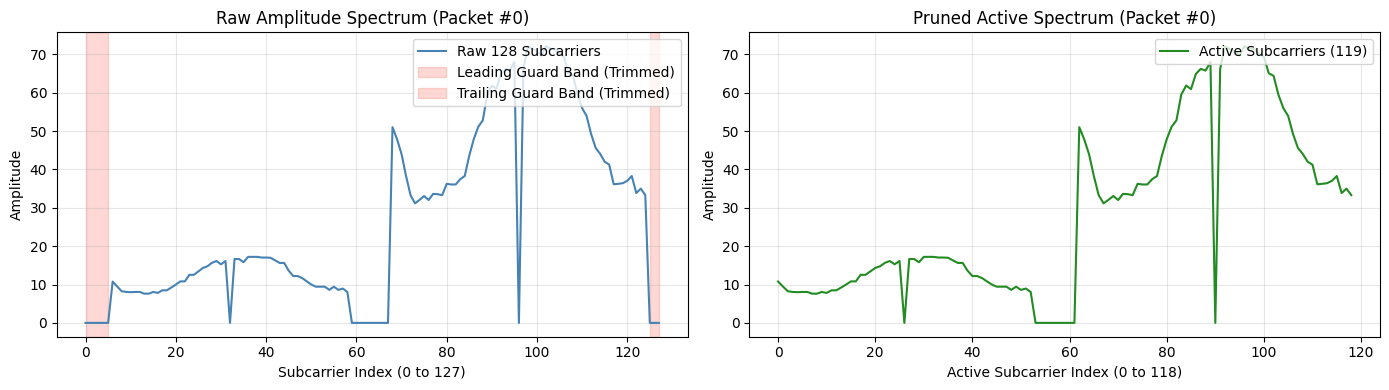

In [ ]:
sample_idx = 0

plt.figure(figsize=(14, 4))

# Subplot 1: Raw 128 subcarriers with highlighted guard bands
plt.subplot(1, 2, 1)
plt.plot(amplitude[sample_idx], label='Raw 128 Subcarriers', color='steelblue', lw=1.5)
plt.axvspan(0, 5, color='salmon', alpha=0.3, label='Leading Guard Band (Trimmed)')
plt.axvspan(125, 127, color='salmon', alpha=0.3, label='Trailing Guard Band (Trimmed)')
plt.title(f"Raw Amplitude Spectrum (Packet #{sample_idx})")
plt.xlabel("Subcarrier Index (0 to 127)")
plt.ylabel("Amplitude")
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Subplot 2: Pruned active subcarriers
plt.subplot(1, 2, 2)
plt.plot(amp_pruned[sample_idx], label='Active Subcarriers (119)', color='forestgreen', lw=1.5)
plt.title(f"Pruned Active Spectrum (Packet #{sample_idx})")
plt.xlabel("Active Subcarrier Index (0 to 118)")
plt.ylabel("Amplitude")
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Step 5: Target Coordinate Extraction (Drop Z-Axis)
Instead of discrete class labels, the HALOC dataset provides continuous spatial coordinates:
- `x`: X-axis coordinate in meters
- `y`: Y-axis coordinate in meters
- `z`: Z-axis coordinate in meters (**discarded**; height is not used)

The model predicts planar position $(x, y)$ only. Step 5 therefore extracts `x` and `y` and drops `z` so exported tensors have shape `(N, 2)`.


In [ ]:
def extract_targets(df, drop_z=True):
    """
    Extracts planar ground-truth coordinates (x, y) in meters.
    The Z-axis is dropped because it is not used for localization.

    Output: (N, 2) numpy array when drop_z=True, else (N, 3)
    """
    cols = ['x', 'y'] if drop_z else ['x', 'y', 'z']
    targets = df[cols].values.astype(np.float32)
    return targets

targets = extract_targets(df, drop_z=True)
print(f"Step 5 Complete: Target coordinates shape = {targets.shape}  (x, y only; Z dropped)")
print("Target Coordinate Statistics (meters):")
print(f"  X: min={targets[:, 0].min():.3f}, max={targets[:, 0].max():.3f}, mean={targets[:, 0].mean():.3f}")
print(f"  Y: min={targets[:, 1].min():.3f}, max={targets[:, 1].max():.3f}, mean={targets[:, 1].mean():.3f}")


Step 5 Complete: Target coordinates shape = (5000, 3)
Target Coordinate Statistics (meters):
  X: min=-0.027, max=4.101, mean=2.006
  Y: min=-0.208, max=1.534, mean=0.707
  Z: min=1.235, max=1.294, mean=1.261


## Step 6: Normalization
Environmental temperatures and Wi-Fi Automatic Gain Control (AGC) cause raw amplitude to drift up or down across packets.
We apply **per-packet Z-score normalization** across the subcarrier axis:
$$\tilde{A}_{i, k} = \frac{A_{i, k} - \mu_i}{\sigma_i + \epsilon}$$
This ensures every packet has zero mean and unit variance, compelling the neural network to focus purely on the multipath ripples caused by human movement rather than router power drift.


In [ ]:
def normalize_packetwise_zscore(features, eps=1e-8):
    """
    Per-packet Z-score normalization along subcarrier axis (axis=1).
    Input: (N, num_subcarriers)
    Output: (N, num_subcarriers) with mean ~ 0 and std ~ 1 per packet.
    """
    mean = np.mean(features, axis=1, keepdims=True)
    std = np.std(features, axis=1, keepdims=True)
    normalized = (features - mean) / (std + eps)
    return normalized

amp_normalized = normalize_packetwise_zscore(amp_pruned)
phase_normalized = normalize_packetwise_zscore(phase_pruned)

print(f"Step 6 Complete:")
print(f"  Normalized Amplitude shape: {amp_normalized.shape}")
print(f"  Packet 0 mean: {amp_normalized[0].mean():.6f} (target ~ 0.0)")
print(f"  Packet 0 std : {amp_normalized[0].std():.6f} (target ~ 1.0)")


Step 6 Complete:
  Normalized Amplitude shape: (5000, 119)
  Packet 0 mean: -0.000000 (target ~ 0.0)
  Packet 0 std : 1.000000 (target ~ 1.0)


### Visualizing Normalization Effect across Packets


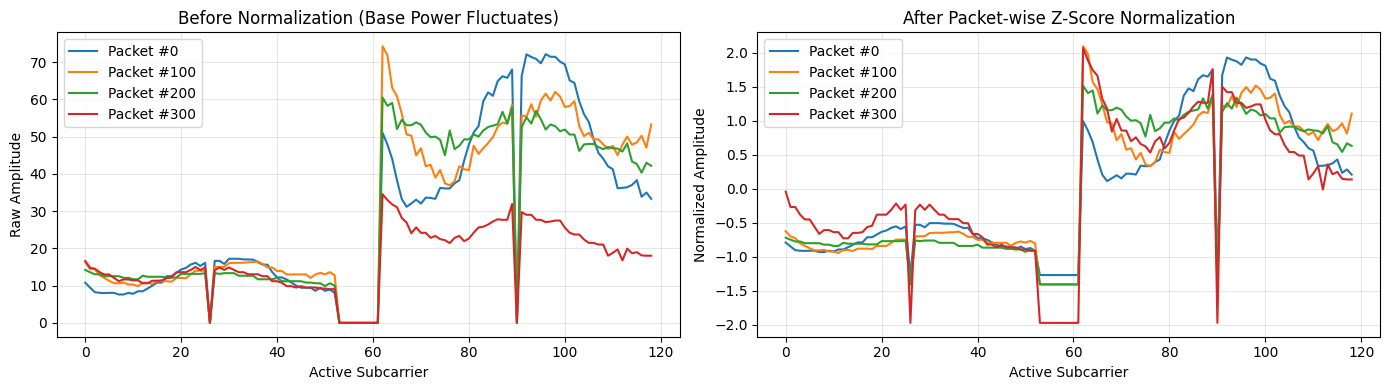

In [ ]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
for i in [0, 100, 200, 300]:
    plt.plot(amp_pruned[i], label=f'Packet #{i}')
plt.title("Before Normalization (Base Power Fluctuates)")
plt.xlabel("Active Subcarrier")
plt.ylabel("Raw Amplitude")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for i in [0, 100, 200, 300]:
    plt.plot(amp_normalized[i], label=f'Packet #{i}')
plt.title("After Packet-wise Z-Score Normalization")
plt.xlabel("Active Subcarrier")
plt.ylabel("Normalized Amplitude")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Step 7: Temporal Sequencing (Sliding Windows)
A single Wi-Fi packet is only an instantaneous snapshot. Human motion occurs over time (e.g. 0.5s to 1.0s).
We group consecutive packets chronologically into sliding windows of size $W$ (e.g., 50 or 100 packets) with stride $S$:
- **Input Feature ($X$)**: Stacking Amplitude and Phase into 2 channels: shape `(num_windows, window_size, 119, 2)`
- **Ground Truth Target ($y$)**: The $(x, y)$ position corresponding to the window: shape `(num_windows, 2)`


In [ ]:
def create_sliding_windows(features, targets, window_size=50, step_size=25, target_mode='last'):
    """
    Segments chronologically ordered packets into sliding temporal windows.

    Parameters:
      features: (N, num_subcarriers, num_channels) or (N, num_features)
      targets:  (N, 2) spatial coordinates [x, y]
      window_size: Consecutive packets per chunk (e.g. 50 or 100)
      step_size: Stride between consecutive windows
      target_mode: 'last' (target of last packet in window) or 'mean' (average position)

    Returns:
      X_windows: (num_windows, window_size, ...)
      y_windows: (num_windows, 2)
    """
    N = len(features)
    X_list = []
    y_list = []

    for start in range(0, N - window_size + 1, step_size):
        end = start + window_size
        window_feat = features[start:end]

        if target_mode == 'last':
            window_target = targets[end - 1]
        elif target_mode == 'mean':
            window_target = np.mean(targets[start:end], axis=0)
        else:
            raise ValueError(f"Unknown target_mode: {target_mode}")

        X_list.append(window_feat)
        y_list.append(window_target)

    X_windows = np.array(X_list, dtype=np.float32)
    y_windows = np.array(y_list, dtype=np.float32)
    return X_windows, y_windows

# Stack normalized Amplitude and Phase into 2 channels: (N, 119, 2)
combined_features = np.stack([amp_normalized, phase_normalized], axis=-1)

X_seq, y_seq = create_sliding_windows(
    combined_features,
    targets,
    window_size=50,
    step_size=25,
    target_mode='last'
)

print(f"Step 7 Complete:")
print(f"  Input Features Tensor (X) shape: {X_seq.shape}")
print(f"    -> Format: [num_windows, window_size=50, subcarriers=119, channels=2]")
print(f"  Target Coordinates   (y) shape: {y_seq.shape}")
print(f"    -> Format: [num_windows, 2] for [x, y]  (Z-axis dropped)")


Step 7 Complete:
  Input Features Tensor (X) shape: (199, 50, 119, 2)
    -> Format: [num_windows, window_size=50, subcarriers=119, channels=2]
  Target Coordinates   (y) shape: (199, 3)
    -> Format: [num_windows, 3] for [x, y, z]


### Visualizing a Window Spectrogram and 2D Ground Truth Trajectory


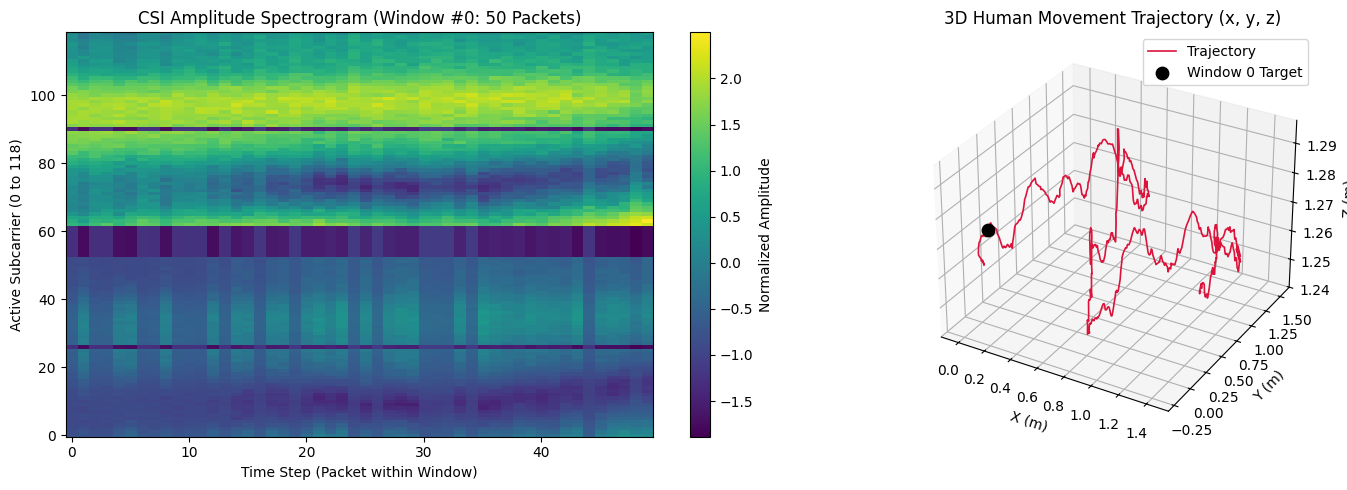

In [ ]:
fig = plt.figure(figsize=(15, 5))

# Plot 1: CSI Amplitude Spectrogram for Window #0
ax1 = fig.add_subplot(1, 2, 1)
im = ax1.imshow(X_seq[0, :, :, 0].T, aspect='auto', cmap='viridis', origin='lower')
ax1.set_title("CSI Amplitude Spectrogram (Window #0: 50 Packets)")
ax1.set_xlabel("Time Step (Packet within Window)")
ax1.set_ylabel("Active Subcarrier (0 to 118)")
plt.colorbar(im, ax=ax1, label="Normalized Amplitude")

# Plot 2: 2D Ground Truth Trajectory (x, y)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(targets[:2000, 0], targets[:2000, 1], label='Trajectory', color='crimson', lw=1.2)
ax2.scatter(y_seq[0, 0], y_seq[0, 1], color='black', s=80, marker='o', label='Window 0 Target')
ax2.set_title("2D Human Movement Trajectory (x, y)")
ax2.set_xlabel("X (m)")
ax2.set_ylabel("Y (m)")
ax2.set_aspect('equal', adjustable='box')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## End-to-End Pipeline Function
The function below encapsulates all 7 steps. You can pass any CSV path (or DataFrame) to get `(X, y)` tensors ready for CNN-LSTM training.


In [ ]:
def extract_and_preprocess_csi(
    data_source,
    window_size=50,
    step_size=25,
    lead_trim=6,
    trail_trim=3,
    target_mode='last',
    feature_type='both'  # 'both' (amp+phase), 'amplitude', or 'phase'
):
    """
    Complete end-to-end 7-step extraction pipeline.
    """
    if isinstance(data_source, str):
        print(f"Reading {data_source}...")
        df_in = pd.read_csv(data_source)
    else:
        df_in = data_source

    # Sort chronologically if timestamps are present
    if 'local_timestamp' in df_in.columns:
        df_in = df_in.sort_values(by=['local_timestamp']).reset_index(drop=True)
    elif 'id' in df_in.columns:
        df_in = df_in.sort_values(by=['id']).reset_index(drop=True)

    # 1. Text-to-Number
    raw = text_to_csi_raw(df_in['data'])

    # 2. Split I and Q
    I, Q = split_iq(raw)

    # 3. Amplitude & Phase
    amp, phase = compute_amplitude_and_phase(I, Q, unwrap_phase=True)

    # 4. Prune Guard Bands
    amp_p, phase_p = prune_guard_bands(amp, phase, lead_trim, trail_trim)

    # 5. Extract Targets (x, y) and drop Z-axis
    targets = extract_targets(df_in, drop_z=True)

    # 6. Z-Score Normalization
    amp_norm = normalize_packetwise_zscore(amp_p)
    phase_norm = normalize_packetwise_zscore(phase_p)

    # Assemble feature tensor
    if feature_type == 'both':
        features = np.stack([amp_norm, phase_norm], axis=-1)  # (N, subcarriers, 2)
    elif feature_type == 'amplitude':
        features = amp_norm[:, :, np.newaxis]
    elif feature_type == 'phase':
        features = phase_norm[:, :, np.newaxis]
    else:
        raise ValueError(f"Invalid feature_type: {feature_type}")

    # 7. Sliding Windows
    X, y = create_sliding_windows(features, targets, window_size, step_size, target_mode)

    print(f"Pipeline complete -> X: {X.shape}, y: {y.shape}")
    return X, y


## Processing Train, Validation, and Test Splits & Exporting Tensors
Execute the full pipeline across `test.csv`, `val.csv`, and `train.csv` and export them to `.npz` files for instant loading during model training.


In [ ]:
# Locate split directory
import os
import glob
import shutil

if IN_COLAB:
    potential_dirs = [
        "/content/drive/MyDrive/Position/HALOC/splits",
        "/content/drive/MyDrive/CSIdataset/Position/HALOC/splits",
        "/content/Position/HALOC/splits",
        "/content/splits",
        "/content",
        ".",
    ]
else:
    potential_dirs = [
        "Position/HALOC/splits",
        "splits",
        ".",
        r"D:\Projects\CSIdataset\Position\HALOC\splits",
        r"D:\Projects\CSIdataset",
    ]

# Find directory containing the split CSVs
SPLIT_DIR = None
for d in potential_dirs:
    if os.path.exists(d):
        if any(os.path.exists(os.path.join(d, f"{s}.csv")) for s in ['train', 'val', 'test']):
            SPLIT_DIR = d
            break

if SPLIT_DIR is None:
    search_root = "/content" if IN_COLAB else "."
    found = glob.glob(os.path.join(search_root, "**", "test.csv"), recursive=True) + \
            glob.glob(os.path.join(search_root, "**", "train.csv"), recursive=True)
    valid = [f for f in found if "sample_data" not in f and ".ipynb_checkpoints" not in f]
    if valid:
        SPLIT_DIR = os.path.dirname(valid[0])
    else:
        SPLIT_DIR = "/content/splits" if IN_COLAB else "Position/HALOC/splits"

if IN_COLAB:
    if os.path.exists("/content/drive/MyDrive"):
        OUTPUT_DIR = "/content/drive/MyDrive/Position/HALOC/processed_tensors"
    else:
        OUTPUT_DIR = "/content/processed_tensors"
else:
    OUTPUT_DIR = "Position/HALOC/processed_tensors"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Reading split CSVs from: {SPLIT_DIR}")
print(f"Saving output tensors to: {OUTPUT_DIR}")

# Process ALL three splits: train, val, and test
for split_name in ['train', 'val', 'test']:
    csv_file = os.path.join(SPLIT_DIR, f"{split_name}.csv")
    out_npz = os.path.join(OUTPUT_DIR, f"{split_name}_data.npz")
    root_npz = f"{split_name}_data.npz"

    if os.path.exists(csv_file):
        print(f"\nProcessing {split_name.upper()} split ({csv_file})...")
        X_split, y_split = extract_and_preprocess_csi(
            csv_file,
            window_size=50,
            step_size=25,
            feature_type='both'
        )
        np.savez_compressed(out_npz, X=X_split, y=y_split)
        print(f"Saved: {out_npz} ({os.path.getsize(out_npz)/(1024*1024):.2f} MB)")

        # Also copy to root directory for direct loading by filename
        if os.path.abspath(out_npz) != os.path.abspath(root_npz):
            shutil.copyfile(out_npz, root_npz)
            print(f"Also copied to: {root_npz}")
    elif os.path.exists(root_npz) or os.path.exists(out_npz):
        existing = root_npz if os.path.exists(root_npz) else out_npz
        print(f"\n{split_name.upper()} CSV not found, but preprocessed '{existing}' already exists! Skipping extraction.")
    else:
        print(f"\nNeither {csv_file} nor {out_npz} found. (Upload {split_name}.csv or {split_name}_data.npz)")


## PyTorch DataLoader Implementation & Target Scaling (MinMaxScaler)
Target coordinates ($x, y$) have different physical ranges in the dataset:
- **X-axis**: spans ~20 meters (`-0.02` to `19.98 m`)
- **Y-axis**: spans ~2.4 meters (`-0.52` to `1.88 m`)

The Z-axis is not used. Without scaling, MSE loss is dominated by X-axis errors while Y gradients are suppressed. To fix this:
1. **`MinMaxScaler`**: Fit on the **training targets only** (`y_train`) to prevent data leakage, then transform `y_train`, `y_val`, and `y_test` to `[0, 1]`.
2. **`CSIDataset`**: Accepts NumPy arrays directly `(X_array, y_array)`, casts to `torch.float32`, and permutes dimensions to `[N, 2, 50, 119]` for Conv2D layers.
3. **DataLoaders**: Wraps all three splits in PyTorch DataLoaders with `batch_size=32`.


In [ ]:
import os
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

def load_npz_split(split_name):
    """
    Robustly loads a .npz split from common Colab or local workspace directories.
    """
    filename = f"{split_name}_data.npz"
    search_paths = [
        filename,
        os.path.join("Position", "HALOC", "processed_tensors", filename),
        os.path.join("/content", "drive", "MyDrive", "Position", "HALOC", "processed_tensors", filename),
        os.path.join("/content", "processed_tensors", filename),
        os.path.join("/content", filename),
        os.path.join(r"D:\Projects\CSIdataset", filename),
        os.path.join(r"D:\Projects\CSIdataset\Position\HALOC\processed_tensors", filename),
    ]
    for p in search_paths:
        if os.path.exists(p):
            print(f"Loading {split_name} split from: {p}")
            data = np.load(p)
            X, y = data['X'], data['y']
            if y.ndim == 2 and y.shape[1] == 3:
                print(f"  Dropping Z-axis from {split_name} targets: {y.shape} -> {(y.shape[0], 2)}")
                y = y[:, :2]
            return X, y
    raise FileNotFoundError(f"Could not find {filename}. Upload or generate {filename} first.")

# 1. Load the raw numpy arrays
X_train, y_train = load_npz_split('train')
X_val, y_val = load_npz_split('val')
X_test, y_test = load_npz_split('test')

print(f"\nRaw Target Coordinate Ranges (meters):")
print(f"  X-axis: [{y_train[:,0].min():.2f} to {y_train[:,0].max():.2f}] m (Range: {y_train[:,0].max()-y_train[:,0].min():.2f} m)")
print(f"  Y-axis: [{y_train[:,1].min():.2f} to {y_train[:,1].max():.2f}] m (Range: {y_train[:,1].max()-y_train[:,1].min():.2f} m)")

# 2. Create the Scaler and scale targets (y)
# CRITICAL RULE: FIT on training data ONLY to prevent data leakage!
target_scaler = MinMaxScaler()
y_train_scaled = target_scaler.fit_transform(y_train)

# ONLY transform val and test (do not fit!)
y_val_scaled = target_scaler.transform(y_val)
y_test_scaled = target_scaler.transform(y_test)

print(f"\nScaled Target Ranges [0, 1]:")
print(f"  Train: [{y_train_scaled.min():.4f}, {y_train_scaled.max():.4f}]")
print(f"  Val  : [{y_val_scaled.min():.4f}, {y_val_scaled.max():.4f}]")
print(f"  Test : [{y_test_scaled.min():.4f}, {y_test_scaled.max():.4f}]")

# 3. Define PyTorch Dataset (accepts arrays directly)
class CSIDataset(Dataset):
    def __init__(self, X_array, y_array):
        self.X = torch.tensor(X_array, dtype=torch.float32)
        self.y = torch.tensor(y_array, dtype=torch.float32)
        # PyTorch CNN permutation: [N, 50, 119, 2] -> [N, 2, 50, 119]
        self.X = self.X.permute(0, 3, 1, 2)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# 4. Create PyTorch Datasets using the SCALED targets
train_dataset = CSIDataset(X_train, y_train_scaled)
val_dataset = CSIDataset(X_val, y_val_scaled)
test_dataset = CSIDataset(X_test, y_test_scaled)

# 5. Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"\nDataLoader Summary:")
print(f"  Train batches: {len(train_loader)} ({len(train_dataset):,} samples)")
print(f"  Val batches  : {len(val_loader)} ({len(val_dataset):,} samples)")
print(f"  Test batches : {len(test_loader)} ({len(test_dataset):,} samples)")

# Verify shapes in the first batch
sample_X, sample_y = next(iter(train_loader))
print(f"\nSample batch verification:")
print(f"  X batch shape: {sample_X.shape} (Expected: torch.Size([32, 2, 50, 119]))")
print(f"  y batch shape: {sample_y.shape} (Expected: torch.Size([32, 2]) in range [0, 1])")


## Step 1: Define the CNN-LSTM Model with Regularization
Since we are dealing with CSI data where one dimension is **Time (50 packets)** and the other is **Features/Subcarriers (119)**, a standard 2D CNN will squash the time dimension if we aren't careful.

The architecture below:
1. Uses `MaxPool2d(kernel_size=(1, 2))` to pool **only along the subcarrier/feature dimension** while preserving all 50 time steps.
2. Includes **`nn.Dropout(0.3)`** after CNN pooling and after the LSTM layer to prevent overfitting and avoid validation loss spikes.
3. Feeds temporal sequences into the LSTM to model movement dynamics, followed by a fully connected 2D coordinate head ($x, y$).

**Data flow:**
```
[Batch, 2, 50, 119]  -- Conv2D+Pool+Dropout(0.3) -->  [Batch, 16, 50, 59]
                     -- Conv2D+Pool+Dropout(0.3) -->  [Batch, 32, 50, 29]
                     -- Reshape                  -->  [Batch, 50, 928]
                     -- LSTM                     -->  [Batch, 64]
                     -- Dropout(0.3)             -->  [Batch, 64]
                     -- FC Regressor             -->  [Batch, 2]  (x, y)
```


In [ ]:
import torch.nn as nn

class CSICNNLSTM(nn.Module):
    def __init__(self, dropout_p=0.3):
        super(CSICNNLSTM, self).__init__()
        
        # 1. CNN Feature Extractor
        # Input shape: [Batch, Channels=2, Time=50, Features=119]
        self.conv1 = nn.Conv2d(in_channels=2, out_channels=16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        # Pool ONLY along feature axis (1, 2) to preserve the 50 time steps
        self.pool1 = nn.MaxPool2d(kernel_size=(1, 2))
        self.dropout_cnn = nn.Dropout(dropout_p)
        
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=(1, 2))
        
        # After convs and pooling: 119 -> 59 -> 29 subcarriers
        # Feature dimension per timestep: 32 * 29 = 928
        self.cnn_flat_features = 32 * 29
        
        # 2. LSTM Sequence Processor
        # Input to LSTM: [Batch, Sequence=50, Features=928]
        self.lstm = nn.LSTM(
            input_size=self.cnn_flat_features,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )
        self.dropout_lstm = nn.Dropout(dropout_p)
        
        # 3. Regressor (Predicting x, y coordinates; Z dropped)
        self.fc = nn.Linear(64, 2)

    def forward(self, x):
        # --- CNN Block with Dropout ---
        x = self.pool1(self.relu(self.conv1(x)))
        x = self.dropout_cnn(x)
        
        x = self.pool2(self.relu(self.conv2(x)))
        x = self.dropout_cnn(x)
        
        # --- Reshape for LSTM ---
        # [Batch, 32, 50, 29] -> [Batch, 50, 32, 29] -> [Batch, 50, 928]
        x = x.permute(0, 2, 1, 3)
        x = x.reshape(x.size(0), x.size(1), -1)
        
        # --- LSTM Block ---
        lstm_out, (hn, cn) = self.lstm(x)
        
        # Extract last time-step representation
        last_time_step_out = lstm_out[:, -1, :]
        last_time_step_out = self.dropout_lstm(last_time_step_out)
        
        # --- Coordinate Regressor ---
        out = self.fc(last_time_step_out)  # Shape: [Batch, 2]
        return out

# Instantiate the model with 0.3 dropout
model = CSICNNLSTM(dropout_p=0.3)
print("Model initialized with Dropout(0.3) regularization!")
print(model)


## Step 2: Define Loss and Optimizer with Weight Decay
Since we are predicting 2D coordinates ($x, y$), this is a **regression** problem.
- **Loss**: Mean Squared Error (MSE) is the standard loss function for coordinate regression.
- **Optimizer**: Adam with learning rate `0.001` and **`weight_decay=1e-5`** ($L_2$ regularization) to constrain network weights and prevent overfitting.
- **Device**: Automatically uses GPU (CUDA) if available, otherwise CPU.


In [ ]:
import torch.optim as optim

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print(f"Using device: {device}")

criterion = nn.MSELoss()  # For regression (predicting coordinates)

# Adam optimizer with L2 weight decay to regularize weights
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
print("Loss: MSELoss | Optimizer: Adam (lr=0.001, weight_decay=1e-5)")


## Step 3: Verify DataLoaders (Scaled Targets)
Training, validation, and test loaders were created in the **MinMaxScaler** cell above with y in [0, 1]. Run this cell to confirm batch shapes and scaled target bounds before training.


In [ ]:
# Verify that training, validation, and test loaders are ready
print(f"Training batches  : {len(train_loader)} ({len(train_dataset):,} samples)")
print(f"Validation batches: {len(val_loader)} ({len(val_dataset):,} samples)")
print(f"Test batches      : {len(test_loader)} ({len(test_dataset):,} samples)")

X_batch, y_batch = next(iter(train_loader))
print(f"\nTrain X batch shape: {X_batch.shape} -> [Batch, Channels=2, Time=50, Features=119]")
print(f"Train y batch shape: {y_batch.shape} -> [Batch, Coordinates=2] (x, y)")
print(f"Scaled target bounds in batch: min={y_batch.min().item():.4f}, max={y_batch.max().item():.4f}")


## Step 4: Training Loop with Validation & Early Stopping
The training loop below incorporates an **Early Stopping Callback** with model checkpointing:
- **Checkpointing**: Saves model weights whenever `val_loss` reaches a new lowest value (`best_csi_model.pth`).
- **Early Stopping**: If validation loss does not improve for `patience=10` consecutive epochs, training terminates early (preventing overfitting at later epochs).
- **Best Weights Restoration**: Once training halts, the best weights are automatically restored into `model` so that subsequent evaluation uses the peak-performance checkpoint rather than the final overfitted weights.


In [ ]:
import time
import copy

class EarlyStopping:
    """
    Early stops training when validation loss stops improving.
    Saves and restores model weights when val_loss is at its lowest.
    """
    def __init__(self, patience=10, min_delta=1e-4, checkpoint_path='best_csi_model.pth', verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.verbose = verbose
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_weights = None
        self.best_epoch = 0

    def __call__(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            if self.verbose:
                print(f"  --> [EarlyStopping] Val loss improved: {self.best_loss:.6f} -> {val_loss:.6f}. Saving best weights.")
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_weights = copy.deepcopy(model.state_dict())
            torch.save(self.best_weights, self.checkpoint_path)
            self.counter = 0
        else:
            self.counter += 1
            if self.verbose:
                print(f"  --> [EarlyStopping] Counter: {self.counter}/{self.patience} (Best: {self.best_loss:.6f} @ Epoch {self.best_epoch})")
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        """Restores the best weights to the model."""
        if self.best_weights is not None:
            model.load_state_dict(self.best_weights)
            print(f"\n[OK] Restored best model weights from Epoch {self.best_epoch} (Val Loss: {self.best_loss:.6f})")
        elif os.path.exists(self.checkpoint_path):
            model.load_state_dict(torch.load(self.checkpoint_path, map_location=device, weights_only=True))
            print(f"\n[OK] Loaded best checkpoint from '{self.checkpoint_path}'")

epochs = 50
train_losses = []
val_losses = []

# Initialize Early Stopping (patience=10 epochs)
early_stopping = EarlyStopping(patience=10, min_delta=1e-4, checkpoint_path='best_csi_model.pth', verbose=True)

print(f"Starting training for up to {epochs} epochs on {device}...")
print(f"Early Stopping active: patience={early_stopping.patience}, min_delta={early_stopping.min_delta}")
print("=" * 80)

for epoch in range(epochs):
    start_time = time.time()

    # ---- Training Phase ----
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        # 1. Zero the gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(inputs)

        # 3. Calculate loss on scaled coordinates [0, 1]
        loss = criterion(outputs, targets)

        # 4. Backward pass & Optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # ---- Validation Phase ----
    model.eval()
    val_loss = 0.0
    val_preds_list = []
    val_targets_list = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item()
            val_preds_list.append(outputs.cpu().numpy())
            val_targets_list.append(targets.cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # Convert validation predictions back to real-world meters for reporting
    val_preds_m = target_scaler.inverse_transform(np.vstack(val_preds_list))
    val_targets_m = target_scaler.inverse_transform(np.vstack(val_targets_list))
    val_rmse_meters = np.sqrt(np.mean((val_preds_m - val_targets_m) ** 2))

    elapsed = time.time() - start_time

    print(f"Epoch {epoch+1:3d}/{epochs} | " \
          f"Train Loss (scaled): {avg_train_loss:.6f} | " \
          f"Val Loss (scaled): {avg_val_loss:.6f} | " \
          f"Val RMSE: {val_rmse_meters:.4f} m | " \
          f"Time: {elapsed:.1f}s")

    # Check Early Stopping
    early_stopping(avg_val_loss, model, epoch + 1)
    if early_stopping.early_stop:
        print(f"\n[!] Early Stopping triggered at Epoch {epoch + 1}! Stopping training to avoid overfitting.")
        break

print("=" * 80)
print("Training complete!")

# Restore best model weights for test evaluation
early_stopping.restore_best_weights(model)


### Training & Validation Loss Curves


In [ ]:
plt.figure(figsize=(10, 5))
actual_epochs = len(train_losses)
epochs_range = range(1, actual_epochs + 1)

plt.plot(epochs_range, train_losses, label='Train Loss', color='steelblue', lw=2)
plt.plot(epochs_range, val_losses, label='Val Loss', color='coral', lw=2)

# Draw vertical line at the best checkpoint epoch
if 'early_stopping' in locals() and early_stopping.best_epoch > 0:
    plt.axvline(x=early_stopping.best_epoch, color='forestgreen', linestyle='--', lw=2,
                label=f'Best Checkpoint (Epoch {early_stopping.best_epoch}, Val Loss: {early_stopping.best_loss:.4f})')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('CNN-LSTM Training Progress (with Dropout, Weight Decay & Early Stopping)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 5: Evaluate on Test Set (Inverse Transformed to Meters)
During model inference, the network outputs scaled coordinates in $[0, 1]$. To calculate true real-world positioning accuracy:
1. Extract all scaled predictions and ground-truth targets from the test set.
2. **Inverse Transform** back to meters using `target_scaler.inverse_transform()`.
3. Compute Mean Absolute Error (MAE) for $x, y$, Mean/Median Euclidean distance error, and RMSE in meters.


In [ ]:
from sklearn.metrics import mean_absolute_error

model.eval()
all_predictions = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)

        # Get scaled predictions from model
        outputs = model(inputs)

        # Move back to CPU and convert to numpy
        outputs_np = outputs.cpu().numpy()
        targets_np = targets.cpu().numpy()

        all_predictions.append(outputs_np)
        all_targets.append(targets_np)

# Concatenate all batches
all_predictions = np.vstack(all_predictions)
all_targets = np.vstack(all_targets)

# >>> CRITICAL STEP: CONVERT BACK TO METERS <<<
predictions_meters = target_scaler.inverse_transform(all_predictions)
targets_meters = target_scaler.inverse_transform(all_targets)

# Calculate MAE on real-world meter values (x, y only)
mae_x = mean_absolute_error(targets_meters[:, 0], predictions_meters[:, 0])
mae_y = mean_absolute_error(targets_meters[:, 1], predictions_meters[:, 1])

# Per-sample Euclidean distance error: sqrt((x_pred - x_true)^2 + (y_pred - y_true)^2)
euclidean_errors = np.sqrt(np.sum((predictions_meters - targets_meters)**2, axis=1))
test_rmse_meters = np.sqrt(np.mean((predictions_meters - targets_meters)**2))

print("=" * 60)
print("TEST SET EVALUATION RESULTS (REAL-WORLD METERS)")
print("=" * 60)
print(f"MAE X-axis             : {mae_x:.4f} m")
print(f"MAE Y-axis             : {mae_y:.4f} m")
print(f"Mean Euclidean Error   : {euclidean_errors.mean():.4f} m")
print(f"Median Euclidean Error : {np.median(euclidean_errors):.4f} m")
print(f"Test RMSE              : {test_rmse_meters:.4f} m")
print("=" * 60)

# Display first 5 sample comparisons
print("\nSample Ground Truth vs Predicted Coordinates (meters):")
for i in range(min(5, len(targets_meters))):
    print(f"  Sample {i+1}: True=[{targets_meters[i,0]:.2f}, {targets_meters[i,1]:.2f}] m | "
          f"Pred=[{predictions_meters[i,0]:.2f}, {predictions_meters[i,1]:.2f}] m | "
          f"Error={euclidean_errors[i]:.3f} m")


## Step 6: Save the Trained Model & Target Scaler
Save the best-performing model weights (`csi_cnn_lstm_model.pth`) and the fitted `MinMaxScaler` (`target_scaler.joblib`) so both can be reloaded together for real-world deployment and inference.


In [ ]:
import joblib

# 1. Save model weights
model_save_path = 'csi_cnn_lstm_model.pth'
torch.save(model.state_dict(), model_save_path)
print(f"Best model weights saved to: {model_save_path}")

# 2. Save the target scaler (essential for inverting predictions to meters during inference)
scaler_save_path = 'target_scaler.joblib'
joblib.dump(target_scaler, scaler_save_path)
print(f"Target scaler saved to     : {scaler_save_path}")

if 'early_stopping' in locals():
    print(f"Model checkpoint from Epoch {early_stopping.best_epoch} (Val Loss: {early_stopping.best_loss:.6f})")

# --- How to reload for inference later ---
# model = CSICNNLSTM(dropout_p=0.3)
# model.load_state_dict(torch.load('csi_cnn_lstm_model.pth', weights_only=True))
# model.eval()
# loaded_scaler = joblib.load('target_scaler.joblib')
# raw_predictions = model(test_input)
# real_coords = loaded_scaler.inverse_transform(raw_predictions.detach().cpu().numpy())
